# Krok 5. Mnożnik tygodnia roku (E1)
**Wynik z instrukcji:** o ile dany tydzień roku sprzedaje więcej lub mniej niż przeciętny tydzień w grupie (np. grudzień ×2,0, lipiec ×0,5); wygładzony (N−1, N, N+1), Wielkanoc wyrównana. Poziom: `AsId`. Dla wariantu `baseline_2`.

**Jak liczymy.**
1. Sprzedaż dzienną asortymentu dzielimy przez mnożnik dnia tygodnia z kroku 4, żeby usunąć wpływ dnia tygodnia (inaczej tydzień z dużą liczbą sobót wyglądałby na „mocny”).
2. Z dni czystych liczymy poziom każdego tygodnia i dzielimy go przez średni poziom roku. Tak powstaje względny poziom tygodnia w 2023 i w 2024.
3. Mnożnik tygodnia N = średnia z obu lat. Brakujące tygodnie (same dni nieczyste, np. okolice Wielkanocy i Bożego Narodzenia) uzupełnia wygładzenie.
4. **Wygładzenie** (waga 1-2-1 na tygodniach N−1, N, N+1, cyklicznie) uspokaja szum, bo każdy tydzień ma tylko dwie obserwacje.
5. **Wielkanoc wyrównana**: tygodnie wielkanocne są wyłączone z profilu roku (bo wypadają pod innym numerem w każdym roku), a ich efekt liczymy osobno względem tygodnia z Wielkanocą (od −2 do +1).

**Wynik zapisany do:** `dane/eda/wynik_05_mnoznik_tygodnia_roku.csv` i `dane/eda/wynik_05_wielkanoc_tygodnie.csv`. Wymaga kroku 4.

In [1]:
# Ustawienia wspólne: moduł eda_wspolne.py leży obok tego notebooka
import os, sys
sys.path.insert(0, os.getcwd())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_wspolne as ew

ew.wejdz_do_korzenia()      # przechodzi do katalogu głównego projektu (tam, gdzie jest plik z danymi)
ew.styl()
print("Katalog projektu:", os.getcwd(), "| EDA używa danych do", ew.KONIEC_EDA.date(), "(rok testowy", ew.ROK_TEST, "pomijamy)")

Katalog projektu: /Users/mixer/python/analiza_sprzedazy_w_sklepie | EDA używa danych do 2024-12-31 (rok testowy 2025 pomijamy)


## Poziom tygodnia po usunięciu dnia tygodnia
#### Objaśnienie
**Po co.** Zamieniamy dzienną sprzedaż na „poziom dnia”: sprzedaż / mnożnik dnia tygodnia asortymentu (tabela z kroku 4: własny albo profil sklepu). Potem uśredniamy poziom po dniach czystych tygodnia.
**Co robi kod.**
- `norm` to sprzedaż po usunięciu dnia tygodnia, tylko w dniach czystych (poza nimi `NaN`).
- `L` to średni poziom dnia czystego w każdym tygodniu. Tygodnie bez dni czystych (świąteczne, wielkanocne) mają `NaN`.
- `rel` to `L` podzielone przez średni poziom danego roku: **względny** poziom tygodnia, czyli 1,0 oznacza przeciętny tydzień roku. Dzięki temu rok z wyższym poziomem nie przesuwa profilu.
**Jak czytać wynik.** Powinno być po 52 tygodni w każdym roku. Liczba tygodni z `NaN` mówi, ile tygodni musi uzupełnić wygładzenie.

In [2]:
UZYJ_PROMO = ew.ma_kolumne("CzyPromocja")
fa = ew.wczytaj_sprzedaz(("CzyPromocja",) if UZYJ_PROMO else ())
kal = ew.kalendarz()
if UZYJ_PROMO:
    fa = fa[fa["CzyPromocja"] != 1]                                  # jak w kroku 4: promocje poza profilem
pan = ew.panel_dzienny(fa, kal, "AsId")
del fa
pan["SKLEP"] = pan.sum(axis=1)
pan.columns = pan.columns.astype(str)

m4 = ew.wczytaj_wynik("wynik_04_mnoznik_dnia_tygodnia.csv", index_col=0)
m4.index = m4.index.astype(str)
M = m4.loc[pan.columns, ew.DNI[:6]].values                             # asortymenty x 6 dni
dow = kal["DzienTyg"].values
mult = np.where((dow < 6)[:, None], M.T[np.minimum(dow, 5)], np.nan)   # dni x asortymenty
with np.errstate(all="ignore"):
    poziom_dnia = pan.values / mult                                    # sprzedaż bez wpływu dnia tygodnia
poziom_dnia[~kal["Czysty"].values] = np.nan
poziom_dnia[~np.isfinite(poziom_dnia)] = np.nan

tyg = ew.pelne_tygodnie(kal)
nr_dnia_tyg = ((kal.index - tyg[0]).days // 7).values
ok_dni = (nr_dnia_tyg >= 0) & (nr_dnia_tyg < len(tyg))
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    L = pd.DataFrame(poziom_dnia[ok_dni]).groupby(nr_dnia_tyg[ok_dni]).mean().reindex(range(len(tyg))).values   # tygodnie x asortymenty
t23 = np.array([d.year == 2023 for d in tyg]); t24 = ~t23
assert t23.sum() == t24.sum() == 52
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    rel23 = L[t23] / np.nanmean(L[t23], axis=0)
    rel24 = L[t24] / np.nanmean(L[t24], axis=0)
print("Tygodni bez dni czystych (sklep): 2023 =", int(np.isnan(rel23[:, -1]).sum()), "| 2024 =", int(np.isnan(rel24[:, -1]).sum()))

Tygodni bez dni czystych (sklep): 2023 = 6 | 2024 = 6


## Profil roku, wygładzenie i test
#### Objaśnienie
**Po co.** Składamy mnożnik tygodnia z dwóch lat i sprawdzamy, czy wygładzenie pomaga.
**Co robi kod.**
- `profil_surowy` = średnia względnych poziomów z dwóch lat dla każdego numeru tygodnia (`NaN`, gdy w obu latach brakuje).
- `wygladz(p)`: średnia ważona wag 1-2-1 sąsiednich tygodni (cyklicznie: tydzień 52 sąsiaduje z 1). `NaN` w sąsiedztwie są pomijane, więc wygładzenie wypełnia też luki. Tydzień, który mimo to pozostaje pusty, dostaje 1,0 (zapamiętujemy, ile ich jest).
- **Test uczciwości (tylko lata EDA):** uczymy profil na 2023 i oceniamy na 2024. Porównujemy trzy prognozy względnego poziomu 2024: **płaska** (zawsze 1), **surowa** (profil z 2023, `NaN`→1) i **wygładzona**. Błąd to średni błąd bezwzględny ważony sprzedażą asortymentu.
**Jak czytać wynik.** Jeśli wygładzony błąd jest mniejszy od surowego, szum dwóch obserwacji zjada więcej niż wygładzenie dusi szczyty i wygładzenie pomaga. Jeśli większy, wygładzenie rozmywa wąskie szczyty (np. przedświąteczne). Ważne jest też, czy oba pokonują płaską linię.

In [3]:
def wygladz(p, w=(1, 2, 1)):
    n = len(p)
    liczn = np.zeros_like(p, dtype=float); mian = np.zeros_like(p, dtype=float)
    for s, ws in zip((-1, 0, 1), w):
        x = np.roll(p, s, axis=0)
        ok = ~np.isnan(x)
        liczn += np.where(ok, x * ws, 0); mian += np.where(ok, ws, 0)
    with np.errstate(all="ignore"):
        return liczn / mian

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    profil_surowy = np.nanmean(np.stack([rel23, rel24]), axis=0)             # 52 x asortymenty
prof_wygl = wygladz(profil_surowy)
pusty = np.isnan(prof_wygl)
prof_wygl = np.where(pusty, 1.0, prof_wygl)
print("Tygodnie, których nie wypełniło nawet wygładzenie (dostają 1,0), sklep:", int(pusty[:, -1].sum()), "z 52")

# Test: profil z 2023 -> względny poziom 2024
p23 = rel23.copy()
p23_wygl = np.where(np.isnan(wygladz(p23)), 1.0, wygladz(p23))
p23_surowy = np.where(np.isnan(p23), 1.0, p23)
waga = np.nansum(L[t24], axis=0); waga = waga / waga.sum()
def blad(prog):
    e = np.nanmean(np.abs(rel24 - prog), axis=0)                             # po tygodniach, dla każdego asortymentu
    return e
b_plaski, b_surowy, b_wygl = blad(np.ones_like(rel24)), blad(p23_surowy), blad(p23_wygl)
print(pd.Series({"płaska": np.nansum(b_plaski * waga), "surowy profil": np.nansum(b_surowy * waga),
                 "wygładzony profil": np.nansum(b_wygl * waga)}, name="średni błąd względnego poziomu 2024").round(3).to_string())
lepsze = pd.Series(b_wygl < b_surowy, index=pan.columns)
print("Asortymenty, w których wygładzenie pomaga:", int(lepsze.drop("SKLEP").sum()), "z", len(lepsze) - 1)

Tygodnie, których nie wypełniło nawet wygładzenie (dostają 1,0), sklep: 0 z 52
płaska               0.113
surowy profil        0.113
wygładzony profil    0.105
Asortymenty, w których wygładzenie pomaga: 202 z 235


/var/folders/j5/4_q_c3nx7lv_jq3ksc9my2_m0000gn/T/ipykernel_73339/3226943961.py:25: RuntimeWarning: Mean of empty slice
  e = np.nanmean(np.abs(rel24 - prog), axis=0)                             # po tygodniach, dla każdego asortymentu


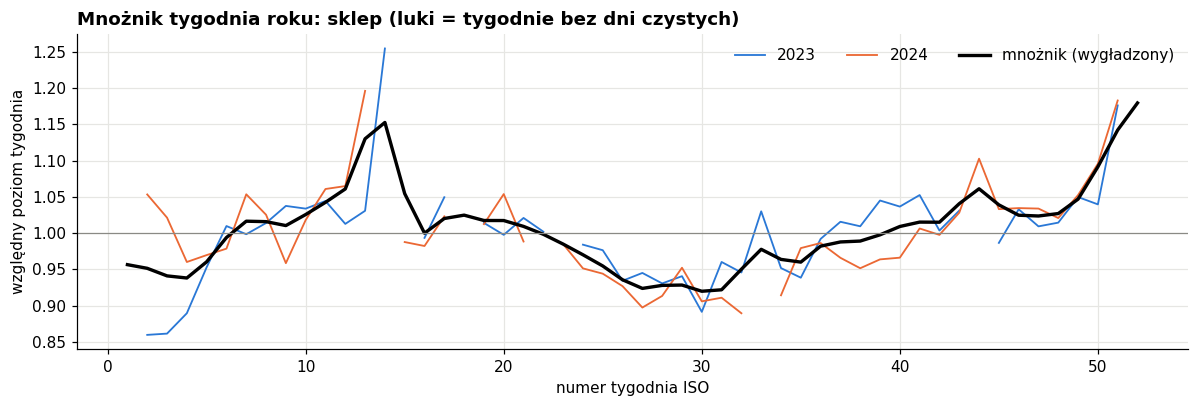

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(1, 53)
ax.plot(x, rel23[:, -1], color=ew.NIEB, lw=1.2, label="2023")
ax.plot(x, rel24[:, -1], color=ew.POM, lw=1.2, label="2024")
ax.plot(x, prof_wygl[:, -1], color="black", lw=2.2, label="mnożnik (wygładzony)")
ax.axhline(1, color=ew.SZARY, lw=0.8)
ax.set_xlabel("numer tygodnia ISO"); ax.set_ylabel("względny poziom tygodnia")
ax.set_title("Mnożnik tygodnia roku: sklep (luki = tygodnie bez dni czystych)"); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.show()

## Wielkanoc wyrównana
#### Objaśnienie
**Po co.** Tygodnie wielkanocne wypadły z profilu roku. Ich efekt liczymy osobno, w położeniu względem Wielkanocy: **k = 0** to tydzień, w którym jest niedziela wielkanocna, **k = −1** tydzień wcześniej (największe zakupy), **k = +1** tydzień po (zaczyna się od poniedziałku wielkanocnego).
**Co robi kod.** Dla każdego asortymentu i roku bierzemy poziom dnia (po usunięciu dnia tygodnia) ze **wszystkich dni otwartych Pn-So** danego tygodnia i dzielimy go przez poziom odniesienia: średnia z tygodni oddalonych od Wielkanocy o 3-6 tygodni w obie strony (z dni czystych). Wynik to mnożnik k-tego tygodnia wielkanocnego, osobno z 2023 i 2024; do wyniku bierzemy średnią.
**Jak czytać wynik.** Mnożnik powyżej 1 w k = −1 oznacza szczyt przedświąteczny. Jeśli wartości z 2023 i 2024 są podobne, wyrównanie względem Wielkanocy jest stabilne (tego nie da się powiedzieć o numerze tygodnia, bo ten przesuwa się między latami).

**Definicja k:**
k = 0 to tydzień od poniedziałku do niedzieli wielkanocnej. Jego dni otwarte Pn–So to ostatnie zakupy przed świętami, więc zwykle jest tam największy szczyt.
k = −1 to zwykły tydzień wcześniej.
k = +1 to tydzień po świętach, który zaczyna się od zamkniętego poniedziałku wielkanocnego.
Jak czytać wynik: mnożnik powyżej 1 w k = 0 oznacza szczyt przedświąteczny, a poniżej 1 w k = +1 spadek po świętach. Mnożniki bliskie 1 w k = −2 i −1 znaczą, że te tygodnie są zwykłe. Różnice rzędu 0,05 to szum.

In [5]:
from dateutil.easter import easter
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    wszystkie_otwarte = np.where((~kal["Zamkniety"].values & (dow < 6))[:, None], pan.values / mult, np.nan)
    wszystkie_otwarte[~np.isfinite(wszystkie_otwarte)] = np.nan
    L_otw = pd.DataFrame(wszystkie_otwarte[ok_dni]).groupby(nr_dnia_tyg[ok_dni]).mean().reindex(range(len(tyg))).values

def nr_tyg_dla(data):
    return int((data - tyg[0]).days // 7)

KS = [-2, -1, 0, 1]
wiersze = []
for k in KS:
    per_rok = []
    for rok in (2023, 2024):
        pn_wlk = pd.Timestamp(easter(rok)) - pd.Timedelta(days=6)         # poniedziałek tygodnia z Wielkanocą
        i0 = nr_tyg_dla(pn_wlk)
        odn = [i0 + j for j in (-6, -5, -4, -3, 3, 4, 5, 6) if 0 <= i0 + j < len(tyg)]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            ref = np.nanmean(L[odn], axis=0)
            per_rok.append(L_otw[i0 + k] / ref)
    wiersze.append(pd.DataFrame({"AsId": pan.columns, "k": k, "mnoznik_2023": per_rok[0], "mnoznik_2024": per_rok[1]}))
wlk = pd.concat(wiersze, ignore_index=True)
wlk["mnoznik"] = wlk[["mnoznik_2023", "mnoznik_2024"]].mean(axis=1)
print("Sklep, mnożnik tygodnia względem Wielkanocy:")
print(wlk[wlk["AsId"] == "SKLEP"].set_index("k")[["mnoznik_2023", "mnoznik_2024", "mnoznik"]].round(2).to_string())

Sklep, mnożnik tygodnia względem Wielkanocy:
    mnoznik_2023  mnoznik_2024  mnoznik
k                                      
-2          0.99          1.05     1.02
-1          1.00          1.05     1.03
0           1.26          1.23     1.25
1           0.95          0.89     0.92


## Zapis
#### Objaśnienie
**Po co.** Zapisujemy dwie tabele: mnożniki tygodni 1-52 (surowy i wygładzony, z flagą wypełnienia) oraz mnożniki tygodni wielkanocnych. Tydzień 53 (występuje w niektórych latach) nie ma własnego mnożnika: przy użyciu tabeli bierzemy dla niego mnożnik tygodnia 52.
**Uwaga.** Mnożnik jest względny wobec średniego tygodnia roku (średnia około 1). Mnożnik 2,0 w grudniu znaczy: tydzień sprzedaje dwa razy więcej niż przeciętny tydzień roku tego asortymentu.

In [6]:
dl = pd.DataFrame({
    "AsId": np.repeat(pan.columns.values, 52),
    "TydzienISO": np.tile(np.arange(1, 53), pan.shape[1]),
    "mnoznik_surowy": profil_surowy.T.ravel(),
    "mnoznik_wygladzony": prof_wygl.T.ravel(),
    "wypelniony": pusty.T.ravel(),
})
ew.zapisz_wynik(dl, "wynik_05_mnoznik_tygodnia_roku.csv", index=False)
ew.zapisz_wynik(wlk, "wynik_05_wielkanoc_tygodnie.csv", index=False)

Zapisano: dane/eda/wynik_05_mnoznik_tygodnia_roku.csv (12272 wierszy)
Zapisano: dane/eda/wynik_05_wielkanoc_tygodnie.csv (944 wierszy)


'dane/eda/wynik_05_wielkanoc_tygodnie.csv'